In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score
)

In [3]:
df = pd.read_csv("air_quality_dataset.csv")

In [4]:
print("FIRST FIVE ROWS")
print(df.head())
print("\nDataset shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nSummary statistics:\n", df.describe())


FIRST FIVE ROWS
        PM2.5        PM10         NOx        NO2        SO2        VOCs  \
0   39.967142   57.926035  116.192213  55.230299   4.531693   75.317261   
1  101.935672  150.774299   76.826826  79.051618  18.744780  145.083987   
2   70.996192  138.948796  158.731020  60.466604  14.892239  145.147338   
3   28.464728   63.643900   25.385343  15.333286   7.647429  130.022319   
4   78.265276  113.977926  105.644340  59.202337  17.696806  181.713667   

         CO         CO2       CH4  Temperature  
0  2.789606  427.674347  1.706105    31.085120  
1  1.966569  529.739619  2.492663    33.711103  
2  2.626446  499.889443  2.431165    33.778698  
3  1.779360  388.283712  1.818563    31.565877  
4  3.240533  464.739197  2.597225    32.229835  

Dataset shape: (500, 10)

Missing values:
 PM2.5          0
PM10           0
NOx            0
NO2            0
SO2            0
VOCs           0
CO             0
CO2            0
CH4            0
Temperature    0
dtype: int64

Duplicate r

In [5]:
median_pm25 = df["PM2.5"].median()
df["PM2.5_Category"] = np.where(
    df["PM2.5"] >= median_pm25, 1, 0
)
# 0 = Lower PM2.5, 1 = Higher PM2.5

print(f"\nDataset median PM2.5 threshold: {median_pm25:.4f}")
print("Class counts (0=Lower, 1=Higher):\n",
      df["PM2.5_Category"].value_counts().sort_index())


Dataset median PM2.5 threshold: 48.0386
Class counts (0=Lower, 1=Higher):
 PM2.5_Category
0    250
1    250
Name: count, dtype: int64


In [6]:
features = [c for c in df.columns if c not in ["PM2.5", "PM2.5_Category"]]
X = df[features]
y = df["PM2.5_Category"]

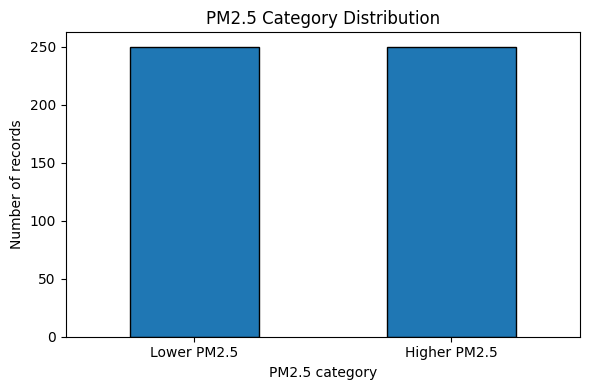

In [7]:
class_counts = y.map({0: "Lower PM2.5", 1: "Higher PM2.5"}).value_counts()
plt.figure(figsize=(6, 4))
class_counts.plot(kind="bar", edgecolor="black")
plt.xlabel("PM2.5 category")
plt.ylabel("Number of records")
plt.title("PM2.5 Category Distribution")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))



Training records: 400
Testing records: 100


In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [10]:
model = LogisticRegression(max_iter=2000, random_state=42)
model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=2000, random_state=42)

In [11]:
y_pred = model.predict(X_test_scaled)
y_probability = model.predict_proba(X_test_scaled)[:, 1]

prediction_results = pd.DataFrame({
    "Actual Category": y_test.map({0: "Lower", 1: "Higher"}).values,
    "Predicted Category": pd.Series(y_pred).map({0: "Lower", 1: "Higher"}).values
})
print("\nACTUAL VS PREDICTED (first 10 records)")
print(prediction_results.head(10).to_string(index=False))



ACTUAL VS PREDICTED (first 10 records)
Actual Category Predicted Category
         Higher             Higher
          Lower              Lower
          Lower              Lower
         Higher              Lower
         Higher              Lower
         Higher             Higher
         Higher             Higher
          Lower              Lower
          Lower              Lower
          Lower              Lower


In [12]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_probability)

print("\nCLASSIFICATION EVALUATION (positive class = Higher PM2.5)")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Lower PM2.5", "Higher PM2.5"],
    zero_division=0
))


CLASSIFICATION EVALUATION (positive class = Higher PM2.5)
Accuracy:  0.8000
Precision: 0.9412
Recall:    0.6400
F1-score:  0.7619
ROC-AUC:   0.8468

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Lower PM2.5       0.73      0.96      0.83        50
Higher PM2.5       0.94      0.64      0.76        50

    accuracy                           0.80       100
   macro avg       0.83      0.80      0.79       100
weighted avg       0.83      0.80      0.79       100



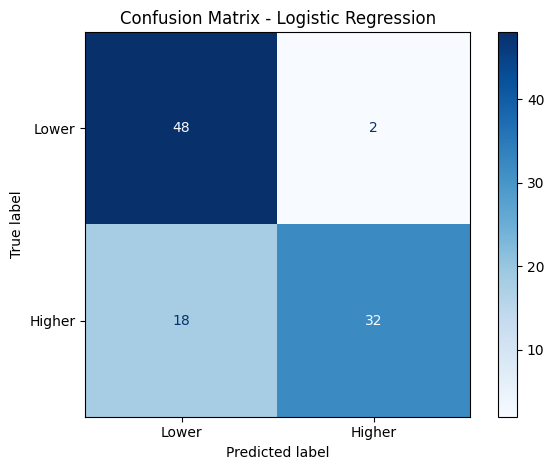

In [13]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Lower", "Higher"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

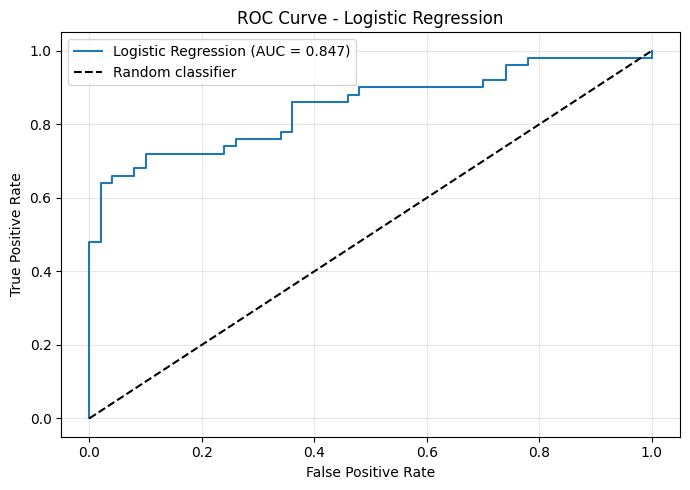

In [14]:
fpr, tpr, thresholds = roc_curve(y_test, y_probability)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
prediction_results.to_csv("logistic_regression_pm25_classification.csv", index=False)
print("\nSaved: logistic_regression_pm25_classification.csv")

print("\nCONCLUSION")
print(
    "Logistic Regression classified records into Lower and Higher PM2.5 "
    "categories relative to the dataset median. The categories are relative "
    "to this dataset and must not be interpreted as official health categories."
)



Saved: logistic_regression_pm25_classification.csv

CONCLUSION
Logistic Regression classified records into Lower and Higher PM2.5 categories relative to the dataset median. The categories are relative to this dataset and must not be interpreted as official health categories.
